# 1. Whole Universe (Residualized)

In [19]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt

from config import (
    OHLCV_DIR, ASSET_DAILY_PATH, ASSETS_PATH,
    DATE_COL, TIMESTAMP_COL, CLOSE_COL, ASSET_ID_COL, MARKET_SYMBOL_COL,
    VOLUME_COL, MIN_VOLUME_24H_USD,
)
from helperfunctions import HelperFunctions
helper = HelperFunctions()

print("Imports OK")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Imports OK


In [20]:
# --- Daten laden & vorverarbeiten ---
from helperfunctions import STABLECOIN_SYMBOLS

# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {ohlcv_df[DATE_COL].min().date()} → {ohlcv_df[DATE_COL].max().date()}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25
OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [21]:
# --- Faktor-Konfiguration ---
# CHAPTER1_FACTOR_COLUMNS: welche(s) Asset(s) werden fuer den Einzel-Deep-Dive in
# Kapitel 1 als Regressor(en) benutzt, um den gemeinsamen Markt-Faktor aus jeder
# anderen Rendite herauszurechnen (siehe helper.residualize_returns). BTC+ETH
# zusammen ist die vollstaendigste Einzelwahl; Kapitel 2 vergleicht dann explizit
# BTC allein, ETH allein und BTC+ETH nebeneinander.
CHAPTER1_FACTOR_COLUMNS = ["BTC", "ETH"]

# Fuer den Vergleich in Kapitel 2:
FACTOR_CHOICES: dict[str, list[str]] = {
    "BTC": ["BTC"],
    "ETH": ["ETH"],
    "BTC+ETH": ["BTC", "ETH"],
}

print(f"Kapitel 1 Faktor: {CHAPTER1_FACTOR_COLUMNS}")
print(f"Kapitel 2 Faktoren zum Vergleich: {list(FACTOR_CHOICES.keys())}")

Kapitel 1 Faktor: ['BTC', 'ETH']
Kapitel 2 Faktoren zum Vergleich: ['BTC', 'ETH', 'BTC+ETH']


In [22]:
# --- Point Cloud erstellen: Lookback + Datum waehlen (residualisiert) ---
import ipywidgets as widgets

data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()
max_lookback_days = (data_max - data_min).days + 1
slider_max_lookback_days = min(100, max_lookback_days)
print(f"Verfuegbare Daten: {data_min} bis {data_max} (max. Lookback: {max_lookback_days} Tage)")

# Werden am Anfang auf None gesetzt und bei jeder ungueltigen Auswahl wieder
# zurueckgesetzt, damit nachfolgende Zellen bei einer fehlgeschlagenen Auswahl
# laut mit einem Fehler abbrechen, statt still das vorherige gueltige Fenster
# weiterzuverwenden.
result = pc = aids = syms = WINDOW_DAYS = DATE = None

def render(lookback_days, date):
    global result, pc, aids, syms, WINDOW_DAYS, DATE

    if date is None:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print("Bitte ein Datum waehlen.")
        return

    if date < data_min or date > data_max:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print(f"Bitte ein Datum zwischen {data_min} und {data_max} waehlen.")
        return

    start_date = date - pd.Timedelta(days=lookback_days - 1)
    if start_date < data_min:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print(
            f"Lookback von {lookback_days} Tagen reicht vor {data_min} zurueck "
            "— kuerzeren Lookback oder spaeteres Datum waehlen."
        )
        return

    date_ts = pd.Timestamp(date, tz="UTC")

    # Rohe Point Cloud bauen (nur Stablecoins ausgeschlossen) -- BTC/ETH muessen
    # enthalten sein, um weiter unten als Regressoren zu dienen.
    result_local = helper.build_point_cloud(
        ohlcv_df         = ohlcv_df,
        universe_df      = universe_df,
        end_date         = date_ts,
        window_size_days = lookback_days,
        exclude_asset_ids= excluded_ids,
    )

    if result_local is None:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print("Keine Daten fuer dieses Fenster — anderen Lookback/Datum waehlen.")
        return

    raw_syms = [id_to_symbol.get(a, f"ID:{a}") for a in result_local["asset_ids"]]
    missing_factors = [f for f in CHAPTER1_FACTOR_COLUMNS if f not in raw_syms]
    if missing_factors:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print(f"Faktor-Asset(s) {missing_factors} an diesem Datum nicht im Universum verfuegbar.")
        return

    raw_returns_df = pd.DataFrame(
        result_local["point_cloud"], columns=raw_syms, index=result_local["timestamps"]
    )
    residual_df = helper.residualize_returns(raw_returns_df, factor_columns=CHAPTER1_FACTOR_COLUMNS)

    # In Notebook-Globals schreiben: pc/syms/aids repraesentieren ab hier die
    # RESIDUALISIERTEN Renditen (Faktor-Spalten entfernt). result behaelt
    # Zeitstempel/Start-/Enddatum der rohen Point Cloud (die aendern sich durch
    # Residualisierung nicht).
    result = result_local
    pc     = residual_df.to_numpy()
    syms   = list(residual_df.columns)
    aids   = [sym_to_id[s] for s in syms]
    WINDOW_DAYS, DATE = lookback_days, date_ts

    print("=" * 55)
    print(f"Faktor (Kapitel 1): {CHAPTER1_FACTOR_COLUMNS}")
    print(f"Fenster:      {result['start_date'].date()} → {result['end_date'].date()}  ({lookback_days} Tage)")
    print(f"Punkte (w):   {result['n_points']}   ← Anzahl 5min-Kerzen")
    print(f"Dimensionen:  {pc.shape[1]}  ← Anzahl Assets (ohne Stablecoins, ohne Faktor-Assets)")
    print(f"Point-Cloud-Shape: {pc.shape}")
    print(f"Assets: {syms}")
    print("=" * 55)
    df_preview = pd.DataFrame(pc[:5], columns=syms, index=result["timestamps"][:5])
    df_preview.index.name = "timestamp"
    display(df_preview.style.format("{:+.4%}"))

lookback_slider = widgets.IntSlider(
    value=min(30, slider_max_lookback_days), min=1, max=slider_max_lookback_days, step=1,
    description="Lookback (Tage):", continuous_update=False,
    style={"description_width": "initial"},
)
date_picker = widgets.DatePicker(description="Datum:", value=data_max, min=data_min, max=data_max)

lookback_minus_button = widgets.Button(description="-1 Tag", layout=widgets.Layout(width="80px"))
lookback_plus_button = widgets.Button(description="+1 Tag", layout=widgets.Layout(width="80px"))

def on_lookback_minus_clicked(button):
    if lookback_slider.value > lookback_slider.min:
        lookback_slider.value -= 1

def on_lookback_plus_clicked(button):
    if lookback_slider.value < lookback_slider.max:
        lookback_slider.value += 1

lookback_minus_button.on_click(on_lookback_minus_clicked)
lookback_plus_button.on_click(on_lookback_plus_clicked)

controls = widgets.interactive(render, lookback_days=lookback_slider, date=date_picker)
display(widgets.VBox([
    widgets.HBox([lookback_slider, lookback_minus_button, lookback_plus_button]),
    date_picker,
    controls.children[-1],
]))

Verfuegbare Daten: 2024-07-23 bis 2026-07-22 (max. Lookback: 730 Tage)


In [23]:
# --- Korrelationsdistanzmatrix aus der (residualisierten) Point Cloud ---
returns_df = pd.DataFrame(pc, columns=syms, index=result["timestamps"])
dist_matrix = helper.correlation_distance(returns_df)

print(f"Distanzmatrix-Shape: {dist_matrix.shape}")
print(f"epsilon-Bereich: [0, {dist_matrix.max():.4f}]  (sqrt(2) = {np.sqrt(2):.4f} = keine Korrelation)")

Distanzmatrix-Shape: (27, 27)
epsilon-Bereich: [0, 1.4118]  (sqrt(2) = 1.4142 = keine Korrelation)


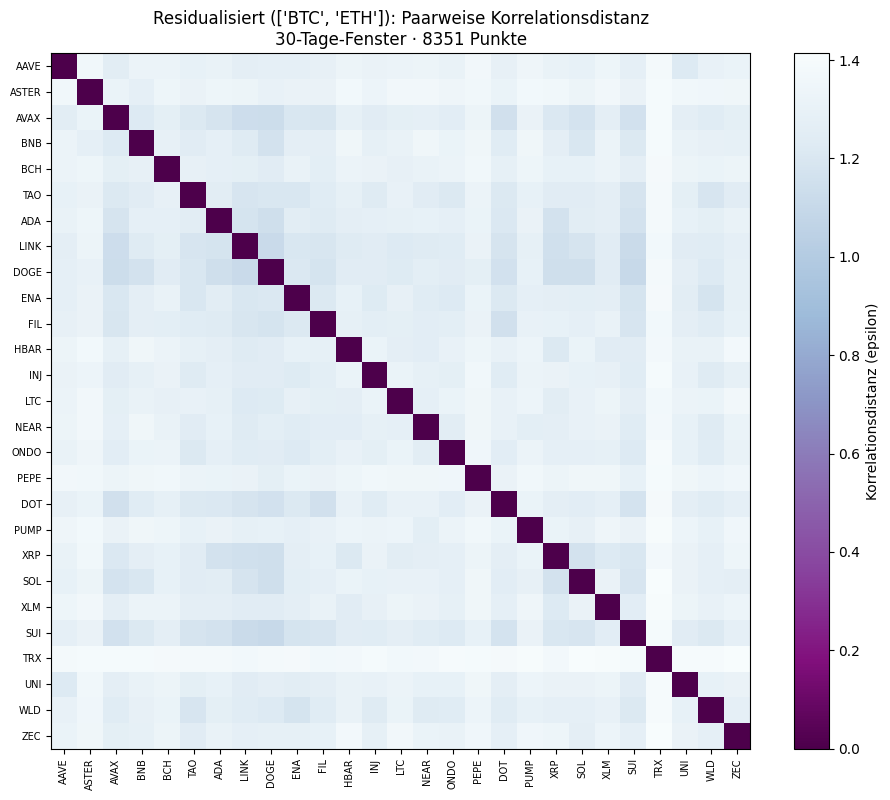

Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):
DOGE  SUI     1.104467
LINK  DOGE    1.113736
      SUI     1.119093
AVAX  DOGE    1.130344
      LINK    1.132987
DOGE  XRP     1.144331
ADA   DOGE    1.146095
DOGE  SOL     1.147415
LINK  XRP     1.149147
AVAX  DOT     1.154656
dtype: float64

Top-5 Paare mit groesster Distanz (am wenigsten verwandt):
ONDO  TRX    1.401053
XLM   TRX    1.405740
PUMP  TRX    1.407029
SOL   TRX    1.409616
TRX   ZEC    1.411801


In [24]:
# --- Visualisierung: Distanz-Heatmap aller Assets (residualisiert) ---
dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)

fig, ax = plt.subplots(figsize=(max(8, len(syms) * 0.35), max(6, len(syms) * 0.3)))
colormax = np.sqrt(2)  # theoretischer Maximalwert (keine Korrelation) -> Farbskala tagesunabhaengig fix
im = ax.imshow(dist_df.values, vmin=0, vmax=colormax, cmap="BuPu_r", aspect="auto")
plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
ax.set_xticks(range(len(syms))); ax.set_xticklabels(syms, rotation=90, fontsize=7)
ax.set_yticks(range(len(syms))); ax.set_yticklabels(syms, fontsize=7)
ax.set_title(f"Residualisiert ({CHAPTER1_FACTOR_COLUMNS}): Paarweise Korrelationsdistanz\n{WINDOW_DAYS}-Tage-Fenster · {result['n_points']} Punkte")
plt.tight_layout()
plt.show()
plt.close("all")

# Kleine Distanz = aehnliches Verhalten -> aufsteigend sortieren fuer die "engsten" Paare.
# .dropna() nach .stack() ist noetig, weil pandas >= 2.1/3.0 die durch .where()
# maskierten (unteres Dreieck) Werte nicht mehr automatisch verwirft -> ohne
# dropna() landen die als NaN maskierten Zellen als "groesste Distanz" ganz am
# Ende der Sortierung (NaN sortiert immer zuletzt), siehe 03_pointclouds.ipynb.
pairs = (
    dist_df.where(np.triu(np.ones(dist_df.shape), k=1).astype(bool))
    .stack()
    .dropna()
    .sort_values(ascending=True)
)
print("Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):")
print(pairs.head(10))
print("\nTop-5 Paare mit groesster Distanz (am wenigsten verwandt):")
print(pairs.tail(5).to_string())

Merge Scale (fest): 1.0


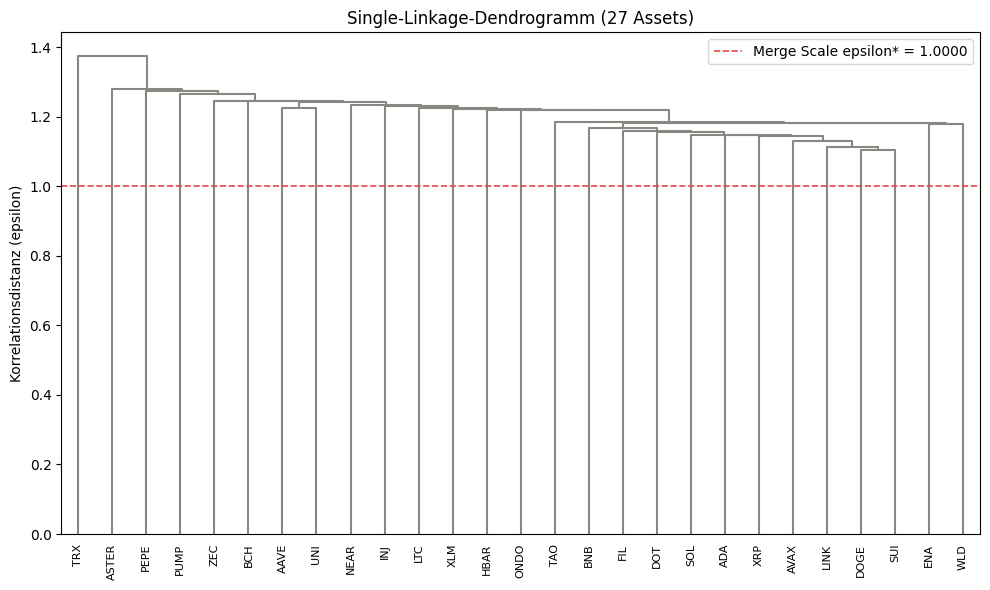

In [25]:
# --- Visualisierung: Dendrogramm der Assets (residualisiert) ---
from cloudvisualisation import plot_dendrogram

# Merge Scale fest auf 1.0, siehe 03_pointclouds.ipynb.
merge_scale = 1.0
print(f"Merge Scale (fest): {merge_scale}")

z_dendro = plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale)

In [26]:
# --- Visualisierung: Epsilon-Slider (Vietoris-Rips 1-Skelett), residualisiert ---
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

plot_vietoris_rips_epsilon_slider(dist_matrix, syms, max_edge_length=np.sqrt(2))

In [27]:
# --- Visualisierung: Cluster-Lebensdauer-Barcode (H0-inspiriert), residualisiert ---
# Hinweis: dies ist NICHT das strikte Vietoris-Rips-H0-Persistenzdiagramm -- siehe
# 03_pointclouds.ipynb fuer die ausfuehrliche Erklaerung dieser Einschraenkung.
from cloudvisualisation import plot_h0_persistence_barcode

z_linkage = plot_h0_persistence_barcode(dist_matrix, syms)

print(f"\nGroesste Merge-Events")
merge_df = pd.DataFrame(z_linkage, columns=["cluster_1", "cluster_2", "death", "size"])
print(merge_df.sort_values("death", ascending=False).head(5).to_string(index=False))

Anzahl Cluster-Intervalle: 52

Groesste Merge-Events
 cluster_1  cluster_2    death  size
      23.0       51.0 1.373714  27.0
       1.0       50.0 1.279972  26.0
      16.0       49.0 1.274092  25.0
      18.0       48.0 1.264454  24.0
      26.0       47.0 1.245327  23.0


In [28]:
# --- Visualisierung: Interaktive 3D Point Cloud (residualisiert) ---
from cloudvisualisation import plot_point_cloud_3d_interactive

plot_point_cloud_3d_interactive(pc, syms, timestamps=result["timestamps"])

  ... 50/701 Daten verarbeitet
  ... 100/701 Daten verarbeitet
  ... 150/701 Daten verarbeitet
  ... 200/701 Daten verarbeitet
  ... 250/701 Daten verarbeitet
  ... 300/701 Daten verarbeitet
  ... 350/701 Daten verarbeitet
  ... 400/701 Daten verarbeitet
  ... 450/701 Daten verarbeitet
  ... 500/701 Daten verarbeitet
  ... 550/701 Daten verarbeitet
  ... 600/701 Daten verarbeitet
  ... 650/701 Daten verarbeitet
  ... 700/701 Daten verarbeitet
Fenster verwendet: 701 von 701 moeglichen Daten (Lookback=30 Tage, Faktor=['BTC', 'ETH'])
Gesamtzahl H0-Persistenzwerte (Merge-Hoehen): 22538


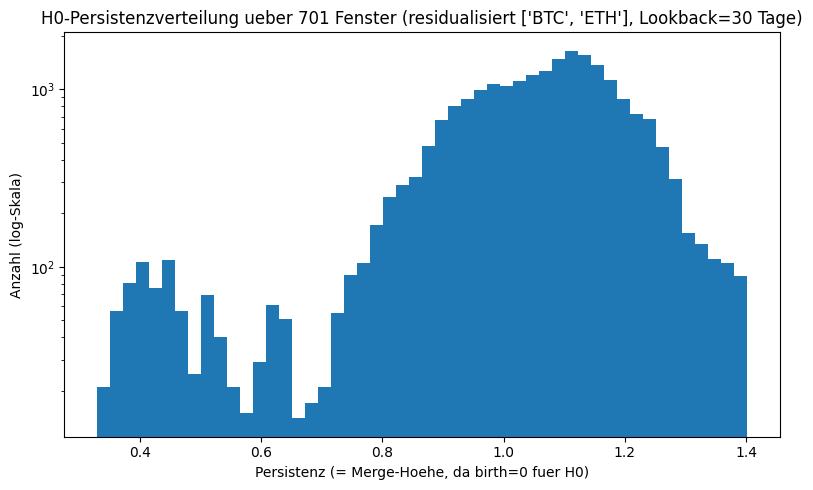

Perzentile:
  50%: 1.0726
  75%: 1.1525
  90%: 1.2242
  95%: 1.2619
  99%: 1.3522


In [29]:
# --- Persistenz-Schwelle bestimmen: Rohverteilung (residualisiert, Kapitel-1-Faktor) ---
# H0-Persistenzwerte = Merge-Hoehen (siehe 03_pointclouds.ipynb). Deckt JEDES
# moegliche Datum ab (keine Stichprobe), bei FESTEM Lookback (WINDOW_DAYS) und
# residualisiert gegen CHAPTER1_FACTOR_COLUMNS.
from scipy.cluster.hierarchy import linkage as _linkage_ph
from scipy.spatial.distance import squareform as _squareform_ph

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    all_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")

    all_persistence_values = []
    n_windows_used = 0

    for i, sample_ts in enumerate(all_dates):
        sample_result = helper.build_point_cloud(
            ohlcv_df         = ohlcv_df,
            universe_df      = universe_df,
            end_date         = sample_ts,
            window_size_days = WINDOW_DAYS,
            exclude_asset_ids= excluded_ids,
        )

        if sample_result is not None:
            sample_syms = [id_to_symbol.get(a, f"ID:{a}") for a in sample_result["asset_ids"]]
            if all(f in sample_syms for f in CHAPTER1_FACTOR_COLUMNS):
                sample_returns_df = pd.DataFrame(
                    sample_result["point_cloud"], columns=sample_syms, index=sample_result["timestamps"]
                )
                sample_residual_df = helper.residualize_returns(
                    sample_returns_df, factor_columns=CHAPTER1_FACTOR_COLUMNS
                )
                if sample_residual_df.shape[1] >= 2:
                    sample_dist_matrix = helper.correlation_distance(sample_residual_df)
                    z = _linkage_ph(_squareform_ph(sample_dist_matrix, checks=False), method="single")
                    all_persistence_values.extend(z[:, 2].tolist())
                    n_windows_used += 1

        if (i + 1) % 50 == 0:
            print(f"  ... {i + 1}/{len(all_dates)} Daten verarbeitet")

    print(f"Fenster verwendet: {n_windows_used} von {len(all_dates)} moeglichen Daten (Lookback={WINDOW_DAYS} Tage, Faktor={CHAPTER1_FACTOR_COLUMNS})")
    print(f"Gesamtzahl H0-Persistenzwerte (Merge-Hoehen): {len(all_persistence_values)}")

    if all_persistence_values:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.hist(all_persistence_values, bins=50)
        ax.set_yscale("log")
        ax.set_xlabel("Persistenz (= Merge-Hoehe, da birth=0 fuer H0)")
        ax.set_ylabel("Anzahl (log-Skala)")
        ax.set_title(f"H0-Persistenzverteilung ueber {n_windows_used} Fenster (residualisiert {CHAPTER1_FACTOR_COLUMNS}, Lookback={WINDOW_DAYS} Tage)")
        plt.tight_layout()
        plt.show()

        percentiles = [50, 75, 90, 95, 99]
        pct_values = np.percentile(all_persistence_values, percentiles)
        print("Perzentile:")
        for p, v in zip(percentiles, pct_values):
            print(f"  {p}%: {v:.4f}")

# 2. Compare Factors (BTC vs. ETH vs. BTC+ETH)

In [30]:
# --- Faktor-Vergleich vorbereiten ---
# Nutzt dieselbe Lookback/Datum-Auswahl wie oben (DATE, WINDOW_DAYS aus der
# Point-Cloud-Zelle in Kapitel 1). Nach einer Aenderung dort diese Zelle erneut
# ausfuehren. Baut fuer jede Faktor-Wahl in FACTOR_CHOICES eine eigene
# residualisierte Point Cloud + Distanzmatrix, aus DERSELBEN rohen Point Cloud
# (nur einmal gebaut, dann pro Faktor-Wahl unterschiedlich residualisiert).
factor_comparison_results: dict = {}

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    raw_result_for_comparison = helper.build_point_cloud(
        ohlcv_df         = ohlcv_df,
        universe_df      = universe_df,
        end_date         = DATE,
        window_size_days = WINDOW_DAYS,
        exclude_asset_ids= excluded_ids,
    )

    if raw_result_for_comparison is None:
        print("Keine Daten fuer dieses Fenster.")
    else:
        raw_syms_for_comparison = [
            id_to_symbol.get(a, f"ID:{a}") for a in raw_result_for_comparison["asset_ids"]
        ]
        raw_returns_df_for_comparison = pd.DataFrame(
            raw_result_for_comparison["point_cloud"],
            columns=raw_syms_for_comparison,
            index=raw_result_for_comparison["timestamps"],
        )

        for factor_name, factor_columns in FACTOR_CHOICES.items():
            missing_factors = [f for f in factor_columns if f not in raw_syms_for_comparison]
            if missing_factors:
                factor_comparison_results[factor_name] = {"status": "missing_factor", "missing": missing_factors}
                continue

            residual_df = helper.residualize_returns(
                raw_returns_df_for_comparison, factor_columns=factor_columns
            )
            dist_matrix_for_factor = helper.correlation_distance(residual_df)

            factor_comparison_results[factor_name] = {
                "status": "ok",
                "syms": list(residual_df.columns),
                "n_members": residual_df.shape[1],
                "dist_matrix": dist_matrix_for_factor,
                "n_points": residual_df.shape[0],
            }

    print(f"Faktor-Vergleich vorbereitet fuer {DATE.date()} ({WINDOW_DAYS} Tage Lookback):")
    for factor_name in FACTOR_CHOICES:
        info = factor_comparison_results.get(factor_name)
        if info is None:
            print(f"  {factor_name}: (nicht vorbereitet)")
        elif info["status"] == "missing_factor":
            print(f"  {factor_name}: Faktor-Asset(s) {info['missing']} an diesem Datum nicht verfuegbar")
        else:
            print(f"  {factor_name}: {info['n_members']} Assets, {info['n_points']} Punkte")

Faktor-Vergleich vorbereitet fuer 2026-07-22 (30 Tage Lookback):
  BTC: 28 Assets, 8351 Punkte
  ETH: 28 Assets, 8351 Punkte
  BTC+ETH: 27 Assets, 8351 Punkte


--- BTC ---


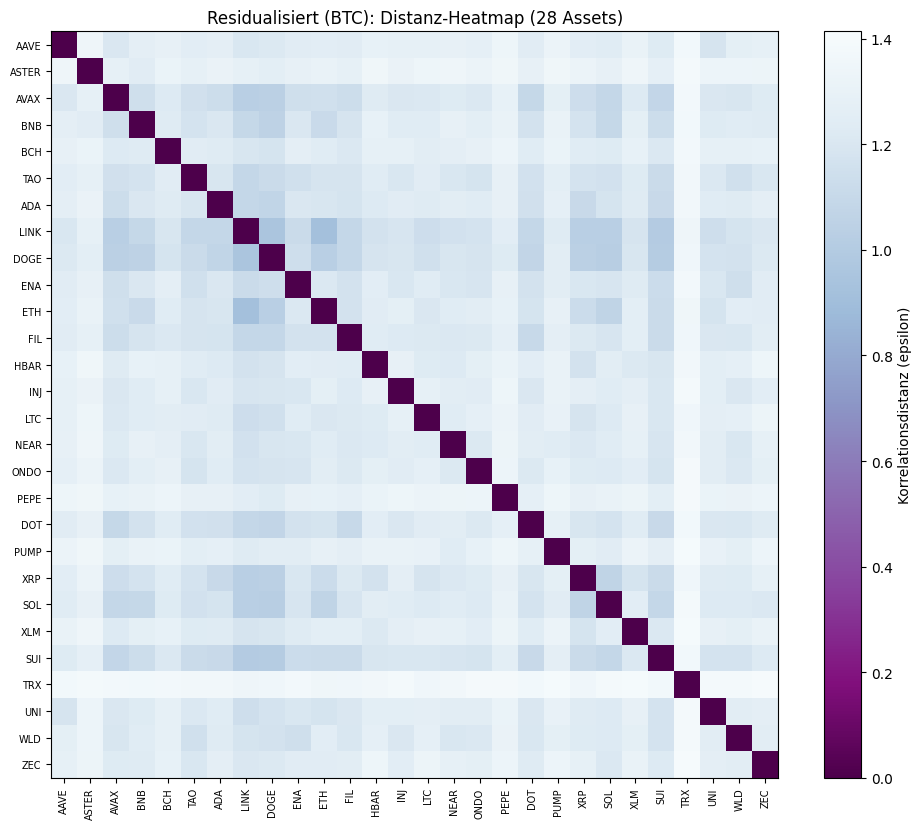

--- ETH ---


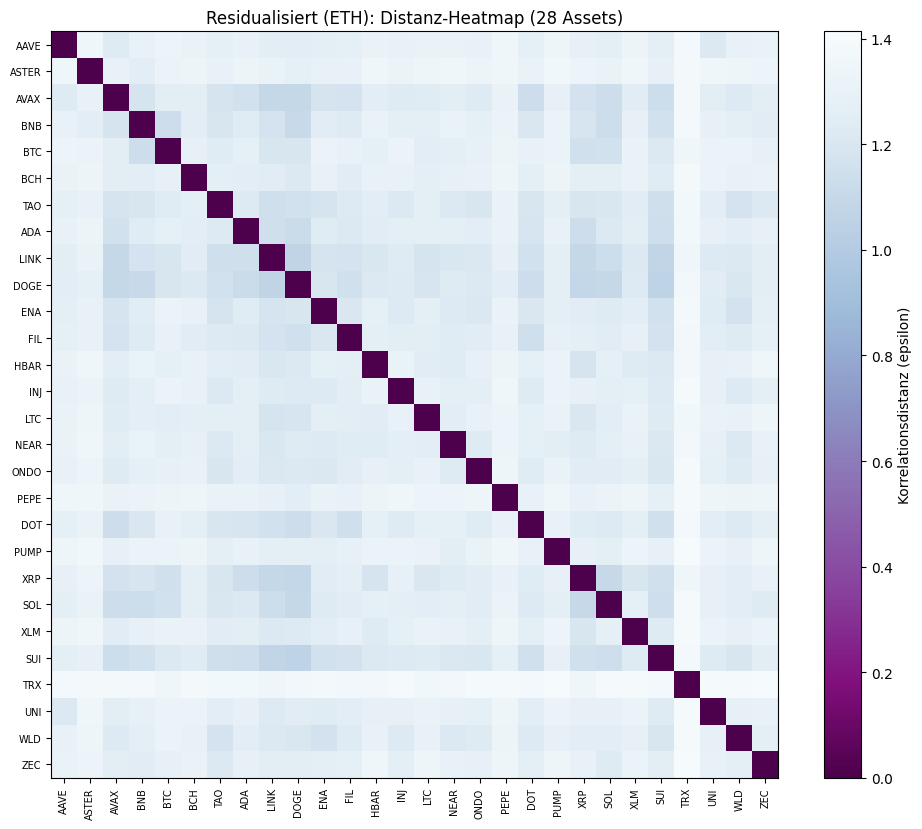

--- BTC+ETH ---


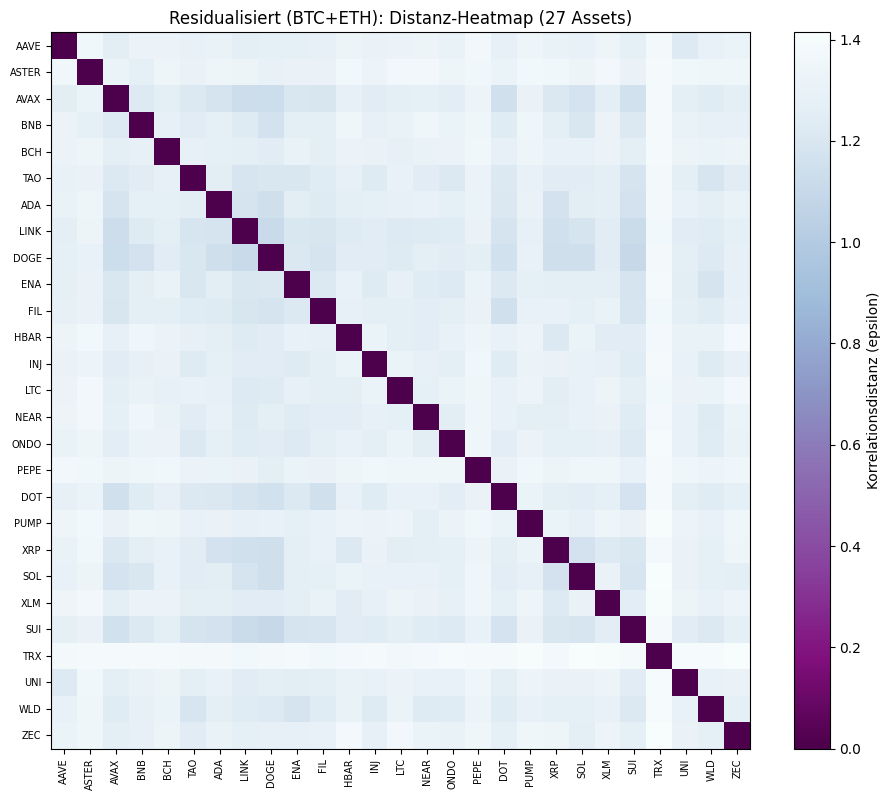

In [31]:
# --- Faktor-Vergleich: Heatmaps ---
for factor_name in FACTOR_CHOICES:
    info = factor_comparison_results.get(factor_name)
    print(f"--- {factor_name} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "missing_factor":
        print(f"Faktor-Asset(s) {info['missing']} an diesem Datum nicht verfuegbar.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]
    n = info["n_members"]

    dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)
    fig, ax = plt.subplots(figsize=(max(6, n * 0.35), max(5, n * 0.3)))
    im = ax.imshow(dist_df.values, vmin=0, vmax=np.sqrt(2), cmap="BuPu_r", aspect="auto")
    plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
    ax.set_xticks(range(n)); ax.set_xticklabels(syms, rotation=90, fontsize=7)
    ax.set_yticks(range(n)); ax.set_yticklabels(syms, fontsize=7)
    ax.set_title(f"Residualisiert ({factor_name}): Distanz-Heatmap ({n} Assets)")
    plt.tight_layout()
    plt.show()
    plt.close("all")

--- BTC ---


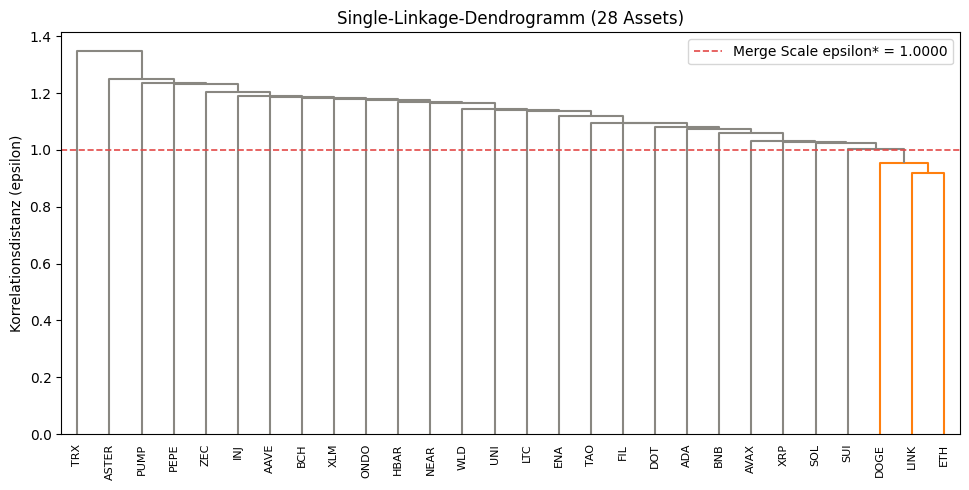

--- ETH ---


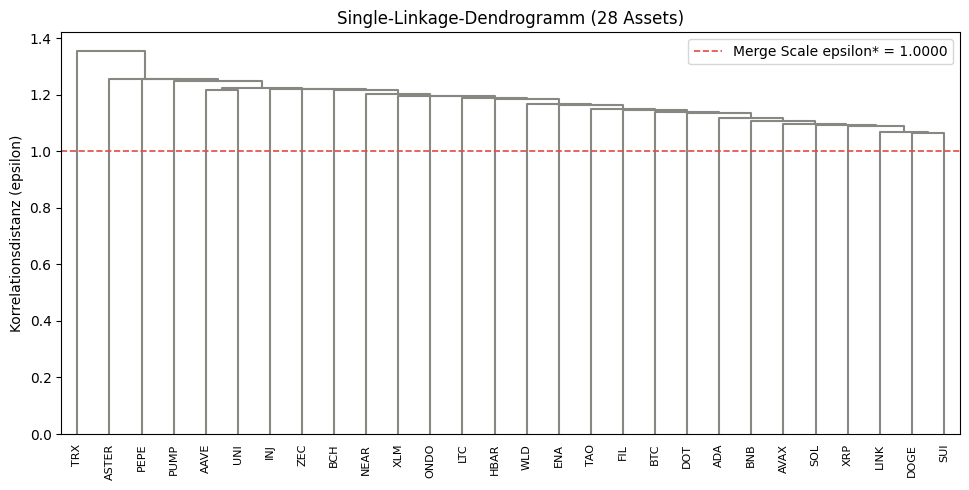

--- BTC+ETH ---


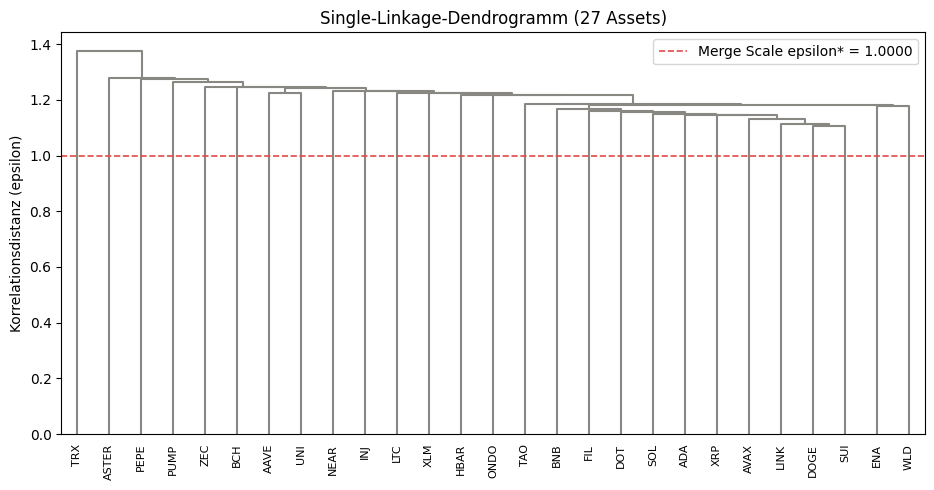

In [32]:
# --- Faktor-Vergleich: Dendrogramme ---
from cloudvisualisation import plot_dendrogram

# Merge Scale fest auf 1.0, gleich fuer alle Faktor-Wahlen.
merge_scale = 1.0

for factor_name in FACTOR_CHOICES:
    info = factor_comparison_results.get(factor_name)
    print(f"--- {factor_name} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "missing_factor":
        print(f"Faktor-Asset(s) {info['missing']} an diesem Datum nicht verfuegbar.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]
    n = info["n_members"]

    plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale, figsize=(max(6, n * 0.35), 5))

In [33]:
# --- Faktor-Vergleich: Vietoris-Rips-Skelette ---
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

for factor_name in FACTOR_CHOICES:
    info = factor_comparison_results.get(factor_name)
    print(f"--- {factor_name} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "missing_factor":
        print(f"Faktor-Asset(s) {info['missing']} an diesem Datum nicht verfuegbar.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]

    plot_vietoris_rips_epsilon_slider(dist_matrix, syms, max_edge_length=np.sqrt(2))

--- BTC ---


--- ETH ---


--- BTC+ETH ---


  ... 50/701 Daten verarbeitet
  ... 100/701 Daten verarbeitet
  ... 150/701 Daten verarbeitet
  ... 200/701 Daten verarbeitet
  ... 250/701 Daten verarbeitet
  ... 300/701 Daten verarbeitet
  ... 350/701 Daten verarbeitet
  ... 400/701 Daten verarbeitet
  ... 450/701 Daten verarbeitet
  ... 500/701 Daten verarbeitet
  ... 550/701 Daten verarbeitet
  ... 600/701 Daten verarbeitet
  ... 650/701 Daten verarbeitet
  ... 700/701 Daten verarbeitet
BTC: 701 von 701 moeglichen Fenstern verwendet, 23239 Persistenzwerte


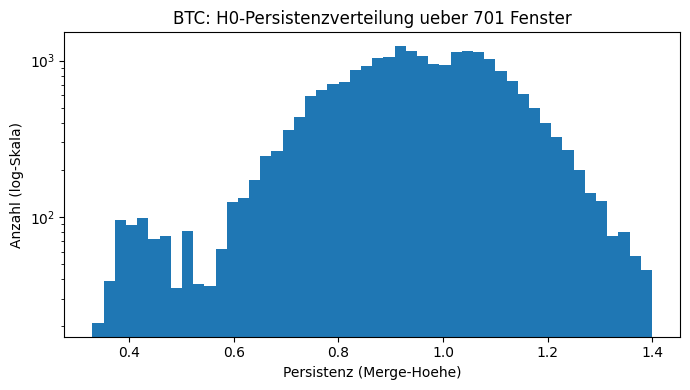

  Perzentile: 50%=0.9545, 75%=1.0721, 90%=1.1598, 95%=1.2180, 99%=1.3175
ETH: 701 von 701 moeglichen Fenstern verwendet, 23239 Persistenzwerte


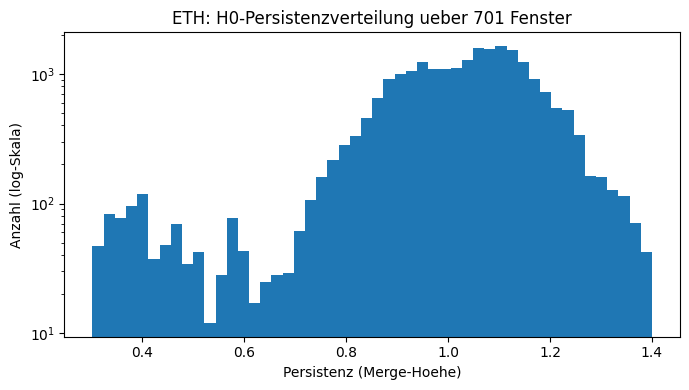

  Perzentile: 50%=1.0436, 75%=1.1244, 90%=1.1951, 95%=1.2399, 99%=1.3333
BTC+ETH: 701 von 701 moeglichen Fenstern verwendet, 22538 Persistenzwerte


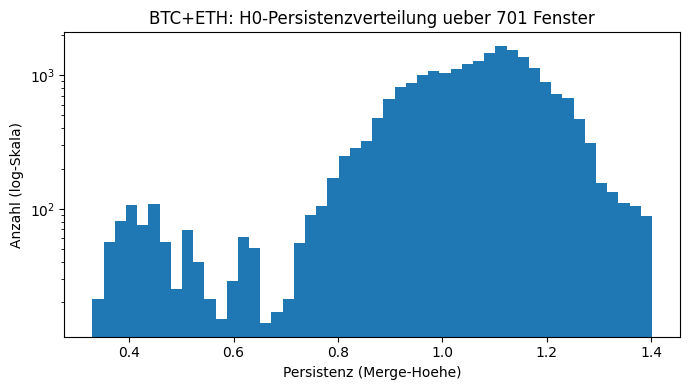

  Perzentile: 50%=1.0726, 75%=1.1525, 90%=1.2242, 95%=1.2619, 99%=1.3522


In [34]:
# --- Faktor-Vergleich: Persistenz-Schwelle bestimmen (Rohverteilung PRO Faktor) ---
# Gleiches Prinzip wie die Kapitel-1-Version, aber fuer jede Faktor-Wahl separat
# gesammelt, aus DERSELBEN rohen Point Cloud pro Datum (nur einmal gebaut, dann
# pro Faktor-Wahl unterschiedlich residualisiert). Keine Stichprobe -> jedes
# moegliche Datum, bei FESTEM WINDOW_DAYS-Lookback.
from scipy.cluster.hierarchy import linkage as _linkage_fph
from scipy.spatial.distance import squareform as _squareform_fph

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    all_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")

    persistence_by_factor: dict[str, list[float]] = {name: [] for name in FACTOR_CHOICES}
    windows_used_by_factor: dict[str, int] = {name: 0 for name in FACTOR_CHOICES}

    for i, sample_ts in enumerate(all_dates):
        sample_result = helper.build_point_cloud(
            ohlcv_df         = ohlcv_df,
            universe_df      = universe_df,
            end_date         = sample_ts,
            window_size_days = WINDOW_DAYS,
            exclude_asset_ids= excluded_ids,
        )

        if sample_result is not None:
            sample_syms = [id_to_symbol.get(a, f"ID:{a}") for a in sample_result["asset_ids"]]
            sample_returns_df = pd.DataFrame(
                sample_result["point_cloud"], columns=sample_syms, index=sample_result["timestamps"]
            )

            for factor_name, factor_columns in FACTOR_CHOICES.items():
                if not all(f in sample_syms for f in factor_columns):
                    continue
                residual_df = helper.residualize_returns(sample_returns_df, factor_columns=factor_columns)
                if residual_df.shape[1] < 2:
                    continue
                dist_matrix = helper.correlation_distance(residual_df)
                z = _linkage_fph(_squareform_fph(dist_matrix, checks=False), method="single")
                persistence_by_factor[factor_name].extend(z[:, 2].tolist())
                windows_used_by_factor[factor_name] += 1

        if (i + 1) % 50 == 0:
            print(f"  ... {i + 1}/{len(all_dates)} Daten verarbeitet")

    for factor_name in FACTOR_CHOICES:
        values = persistence_by_factor[factor_name]
        print(
            f"{factor_name}: {windows_used_by_factor[factor_name]} von {len(all_dates)} "
            f"moeglichen Fenstern verwendet, {len(values)} Persistenzwerte"
        )

        if not values:
            continue

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(values, bins=50)
        ax.set_yscale("log")
        ax.set_xlabel("Persistenz (Merge-Hoehe)")
        ax.set_ylabel("Anzahl (log-Skala)")
        ax.set_title(f"{factor_name}: H0-Persistenzverteilung ueber {windows_used_by_factor[factor_name]} Fenster")
        plt.tight_layout()
        plt.show()

        percentiles = [50, 75, 90, 95, 99]
        pct_values = np.percentile(values, percentiles)
        print("  Perzentile: " + ", ".join(f"{p}%={v:.4f}" for p, v in zip(percentiles, pct_values)))

# 3. Structure Over Time

  ... 50/701 Daten verarbeitet
  ... 100/701 Daten verarbeitet
  ... 150/701 Daten verarbeitet
  ... 200/701 Daten verarbeitet
  ... 250/701 Daten verarbeitet
  ... 300/701 Daten verarbeitet
  ... 350/701 Daten verarbeitet
  ... 400/701 Daten verarbeitet
  ... 450/701 Daten verarbeitet
  ... 500/701 Daten verarbeitet
  ... 550/701 Daten verarbeitet
  ... 600/701 Daten verarbeitet
  ... 650/701 Daten verarbeitet
  ... 700/701 Daten verarbeitet
701 Fenster ausgewertet (Lookback=30 Tage, Faktor=['BTC', 'ETH']).
Fenster mit >=1 Merge unterhalb 0.7: 36 / 701


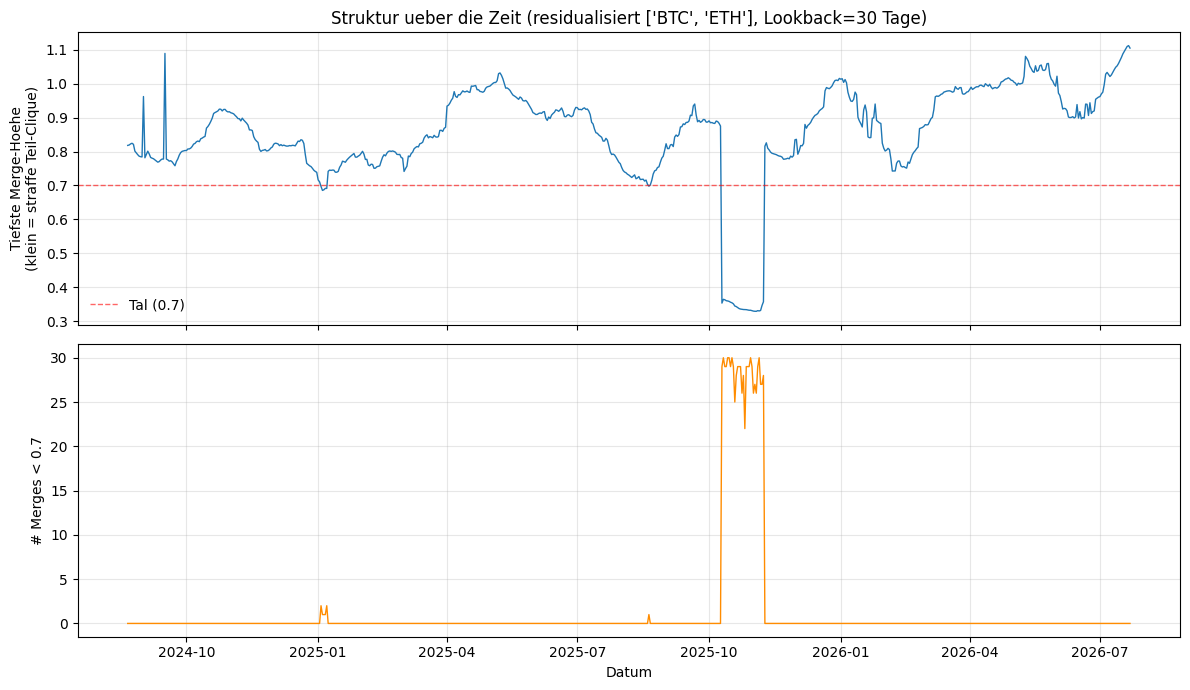

In [35]:
# --- Struktur ueber die Zeit: Tightness & Sub-Valley-Struktur pro Fenster ---
# Fuer jedes moegliche Datum (fester Lookback WINDOW_DAYS, residualisiert gegen
# CHAPTER1_FACTOR_COLUMNS):
#   - min_merge: tiefste Merge-Hoehe im Fenster. Klein = es gibt ein Asset-Paar
#     (oder eine Teil-Clique), das sich deutlich straffer verhaelt als der Rest.
#   - n_below_valley: Anzahl Merges unterhalb VALLEY_THRESHOLD (Naeherung an das
#     Tal in der Kapitel-1-Persistenzverteilung, siehe dort). Auf einem
#     "generischen" Tag ist das meist 0 -- es gibt schlicht nichts unterhalb der
#     Schwelle. Ein deutlicher Ausschlag zeigt an, wann echte Sub-Struktur auftaucht.
#   - below_valley_chain_fraction: von den Merges UNTERHALB der Schwelle, welcher
#     Anteil haengt nur ein einzelnes Asset an eine wachsende Gruppe (statt zwei
#     eigenstaendige Teilgruppen zu verschmelzen). NaN wenn n_below_valley == 0.
#     Hinweis: eine urspruenglich getestete Variante ueber den GESAMTEN Baum (nicht
#     nur unterhalb der Schwelle) unterschied NICHT zwischen einem Tag mit
#     straffer Teil-Clique und einem generischen Tag (~0.88 auf beiden) -- ein
#     einzelnes strukturiertes Merge geht im Rest des ueberwiegend kettenartigen
#     Baums unter. Erst die Beschraenkung auf den Sub-Valley-Bereich macht den
#     Unterschied sichtbar.
from scipy.cluster.hierarchy import linkage as _linkage_sot
from scipy.spatial.distance import squareform as _squareform_sot

VALLEY_THRESHOLD = 0.70


def _below_valley_stats(z: np.ndarray, valley: float) -> tuple[int, float | None]:
    sizes: dict[int, int] = {}
    n = len(z) + 1
    for i in range(n):
        sizes[i] = 1

    below_count = 0
    singleton_joins = 0
    for row_idx, (c1, c2, dist, _count) in enumerate(z):
        c1, c2 = int(c1), int(c2)
        if dist < valley:
            below_count += 1
            if sizes[c1] == 1 or sizes[c2] == 1:
                singleton_joins += 1
        sizes[n + row_idx] = sizes[c1] + sizes[c2]

    chain_fraction = (singleton_joins / below_count) if below_count else None
    return below_count, chain_fraction


if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    all_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")

    structure_rows = []

    for i, sample_ts in enumerate(all_dates):
        sample_result = helper.build_point_cloud(
            ohlcv_df         = ohlcv_df,
            universe_df      = universe_df,
            end_date         = sample_ts,
            window_size_days = WINDOW_DAYS,
            exclude_asset_ids= excluded_ids,
        )

        if sample_result is not None:
            sample_syms = [id_to_symbol.get(a, f"ID:{a}") for a in sample_result["asset_ids"]]
            if all(f in sample_syms for f in CHAPTER1_FACTOR_COLUMNS):
                sample_returns_df = pd.DataFrame(
                    sample_result["point_cloud"], columns=sample_syms, index=sample_result["timestamps"]
                )
                residual_df = helper.residualize_returns(sample_returns_df, factor_columns=CHAPTER1_FACTOR_COLUMNS)
                if residual_df.shape[1] >= 2:
                    dist_matrix = helper.correlation_distance(residual_df)
                    z = _linkage_sot(_squareform_sot(dist_matrix, checks=False), method="single")
                    below_count, below_chain_frac = _below_valley_stats(z, VALLEY_THRESHOLD)
                    structure_rows.append({
                        "date": sample_ts,
                        "min_merge": float(z[:, 2].min()),
                        "n_below_valley": below_count,
                        "below_valley_chain_fraction": below_chain_frac,
                        "n_assets": residual_df.shape[1],
                    })

        if (i + 1) % 50 == 0:
            print(f"  ... {i + 1}/{len(all_dates)} Daten verarbeitet")

    structure_over_time_df = pd.DataFrame(structure_rows).set_index("date")
    print(f"{len(structure_over_time_df)} Fenster ausgewertet (Lookback={WINDOW_DAYS} Tage, Faktor={CHAPTER1_FACTOR_COLUMNS}).")
    print(f"Fenster mit >=1 Merge unterhalb {VALLEY_THRESHOLD}: {(structure_over_time_df['n_below_valley'] > 0).sum()} / {len(structure_over_time_df)}")

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    ax1.plot(structure_over_time_df.index, structure_over_time_df["min_merge"], linewidth=1)
    ax1.axhline(VALLEY_THRESHOLD, color="red", linestyle="--", linewidth=1, alpha=0.6, label=f"Tal ({VALLEY_THRESHOLD})")
    ax1.set_ylabel("Tiefste Merge-Hoehe\n(klein = straffe Teil-Clique)")
    ax1.set_title(f"Struktur ueber die Zeit (residualisiert {CHAPTER1_FACTOR_COLUMNS}, Lookback={WINDOW_DAYS} Tage)")
    ax1.legend(frameon=False)
    ax1.grid(alpha=0.3)

    ax2.plot(structure_over_time_df.index, structure_over_time_df["n_below_valley"], color="darkorange", linewidth=1)
    ax2.set_ylabel(f"# Merges < {VALLEY_THRESHOLD}")
    ax2.set_xlabel("Datum")
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [36]:
# --- Zeit-Slider: Dendrogramm fuer jedes Datum durchblaettern ---
# Baut fuer das gewaehlte Datum (fester Lookback WINDOW_DAYS, residualisiert
# gegen CHAPTER1_FACTOR_COLUMNS) die Point Cloud + Distanzmatrix frisch und zeigt
# das Dendrogramm direkt an, zusammen mit min_merge und n_below_valley (siehe
# vorherige Zelle) fuer genau dieses Fenster -> zum manuellen Durchblaettern der
# Zeitreihe oben (z.B. gezielt zu einem auffaelligen Datum springen).
from IPython.display import clear_output
from cloudvisualisation import plot_dendrogram
from scipy.cluster.hierarchy import linkage as _linkage_slider
from scipy.spatial.distance import squareform as _squareform_slider


def _below_valley_stats_slider(z: np.ndarray, valley: float) -> tuple[int, float | None]:
    n = len(z) + 1
    sizes = {i: 1 for i in range(n)}
    below_count = 0
    singleton_joins = 0
    for row_idx, (c1, c2, dist, _count) in enumerate(z):
        c1, c2 = int(c1), int(c2)
        if dist < valley:
            below_count += 1
            if sizes[c1] == 1 or sizes[c2] == 1:
                singleton_joins += 1
        sizes[n + row_idx] = sizes[c1] + sizes[c2]
    chain_fraction = (singleton_joins / below_count) if below_count else None
    return below_count, chain_fraction


if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    slider_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")

    time_index_slider = widgets.IntSlider(
        value=len(slider_dates) - 1, min=0, max=len(slider_dates) - 1, step=1,
        description="Datum-Index:", continuous_update=False,
        style={"description_width": "initial"}, layout=widgets.Layout(width="500px"),
    )
    time_prev_button = widgets.Button(description="◀ Tag", layout=widgets.Layout(width="70px"))
    time_next_button = widgets.Button(description="Tag ▶", layout=widgets.Layout(width="70px"))
    time_slider_output = widgets.Output()

    def on_time_prev_clicked(button):
        if time_index_slider.value > time_index_slider.min:
            time_index_slider.value -= 1

    def on_time_next_clicked(button):
        if time_index_slider.value < time_index_slider.max:
            time_index_slider.value += 1

    time_prev_button.on_click(on_time_prev_clicked)
    time_next_button.on_click(on_time_next_clicked)

    def render_time_slider(*_change):
        sample_ts = slider_dates[time_index_slider.value]

        with time_slider_output:
            clear_output(wait=True)

            sample_result = helper.build_point_cloud(
                ohlcv_df         = ohlcv_df,
                universe_df      = universe_df,
                end_date         = sample_ts,
                window_size_days = WINDOW_DAYS,
                exclude_asset_ids= excluded_ids,
            )
            if sample_result is None:
                print(f"{sample_ts.date()}: keine Daten fuer dieses Fenster.")
                return

            sample_syms = [id_to_symbol.get(a, f"ID:{a}") for a in sample_result["asset_ids"]]
            missing_factors = [f for f in CHAPTER1_FACTOR_COLUMNS if f not in sample_syms]
            if missing_factors:
                print(f"{sample_ts.date()}: Faktor-Asset(s) {missing_factors} nicht verfuegbar.")
                return

            sample_returns_df = pd.DataFrame(
                sample_result["point_cloud"], columns=sample_syms, index=sample_result["timestamps"]
            )
            residual_df = helper.residualize_returns(sample_returns_df, factor_columns=CHAPTER1_FACTOR_COLUMNS)
            if residual_df.shape[1] < 2:
                print(f"{sample_ts.date()}: zu wenig Assets nach Residualisierung.")
                return

            dist_matrix = helper.correlation_distance(residual_df)
            n_assets = residual_df.shape[1]
            z = _linkage_slider(_squareform_slider(dist_matrix, checks=False), method="single")
            min_merge = float(z[:, 2].min())
            below_count, below_chain_frac = _below_valley_stats_slider(z, VALLEY_THRESHOLD)
            below_chain_frac_str = f"{below_chain_frac:.3f}" if below_chain_frac is not None else "n/a"

            print(
                f"Datum: {sample_ts.date()}  |  Assets: {n_assets}  |  "
                f"min_merge: {min_merge:.4f}  |  Merges < {VALLEY_THRESHOLD}: {below_count}  |  "
                f"davon Singleton-Anschluss: {below_chain_frac_str}"
            )

            # Merge Scale fest auf 1.0, siehe 03_pointclouds.ipynb.
            plot_dendrogram(
                dist_matrix, list(residual_df.columns), color_threshold=1.0,
                figsize=(max(6, n_assets * 0.35), 5),
            )

    time_index_slider.observe(render_time_slider, names="value")
    display(widgets.VBox([
        widgets.HBox([time_index_slider, time_prev_button, time_next_button]),
        time_slider_output,
    ]))
    render_time_slider()